In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [10]:
customer = pd.read_csv("customers.csv")
customer.head()

,monthly_income_k,spending_score
0,81.8,19.3
1,81.4,63.7
2,62.0,50.6
3,33.3,19.8
4,92.7,30.9


In [14]:
print(customer.shape)
print(customer.isnull().sum())
customer.describe().round(1)

(300, 2)
monthly_income_k    0
spending_score      0
dtype: int64


,monthly_income_k,spending_score
count,300.0,300.0
mean,56.7,50.1
std,25.2,26.0
min,18.2,1.6
25%,31.8,25.3
50%,54.8,49.9
75%,81.5,76.2
max,98.1,100.0


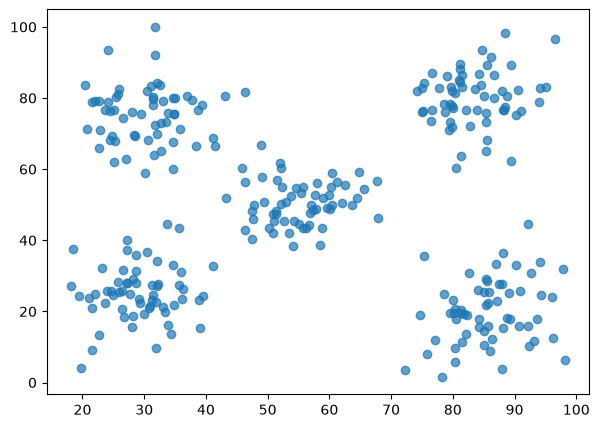

In [16]:
plt.figure(figsize=(7,5))
plt.scatter(customer["monthly_income_k"], customer["spending_score"], alpha=0.7)

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer)
X_scaled[:3].round(2)

array([[ 0.99, -1.19],
       [ 0.98,  0.52],
       [ 0.21,  0.02]])

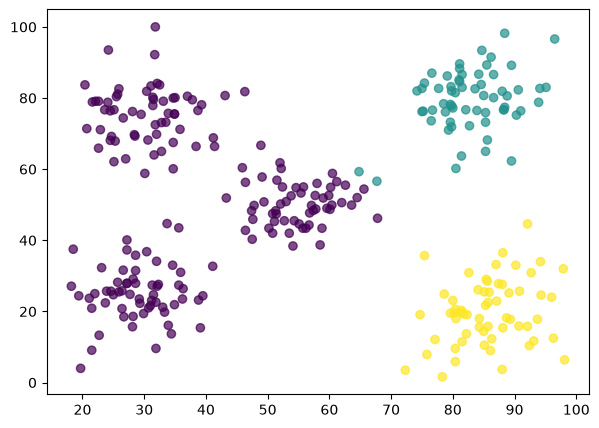

In [25]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
label = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(customer["monthly_income_k"], customer["spending_score"], c=label,  cmap="viridis", alpha=0.7)

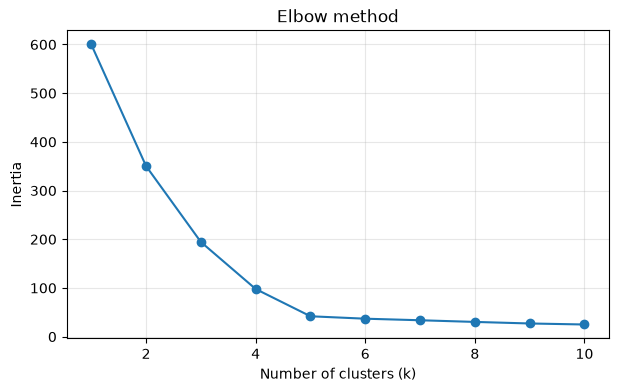

In [26]:
k_values = range(1,11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
final_k = 5
kmeans = KMeans(n_clusters=final_k, random_state=42, n_init=10)
customer["cluster"] = kmeans.fit_predict(X_scaled)


centres = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
plt.scatte